# 7주차 워크북 1 — PDF 문서 검색과 근거 표시 (API 키 불필요) · 완성본 (강의자 시연용)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/itlects/2026-1_ai-convergence-apply/blob/main/Week07/Week07_Workbook1_Complete.ipynb)

**학습목표**
1. PDF에서 페이지별 텍스트를 추출하고 페이지 번호를 근거 정보로 저장한다.
2. 청크 크기(size)와 겹침(overlap)으로 문서를 나누고 차이를 설명한다.
3. TF-IDF 문자 n-gram과 코사인 유사도로 질문에 맞는 근거를 찾는다.
4. 평가 질문(CSV)으로 Top-1·Top-3 정확도를 계산하고 임계값을 정한다.

**실행 방법:** 위에서부터 셀을 하나씩 실행합니다 (`Shift + Enter`).
데이터는 0번 셀이 Google Drive에서 자동으로 내려받습니다.

**노션 따라하기 지시서:** [워크북 1 지시서](https://app.notion.com/p/3ffb2e6bf807819f930fe10a824f5cd3) — 셀 번호마다 코드 설명과 예상 출력이 있습니다.

> 🎓 **강의자 시연 안내**
> - 이 노트북은 학생용과 **코드가 같고**, 실행 결과와 셀별 '강의 포인트', 과제 예시 답안이 들어 있습니다.
> - 수업 전: 런타임 → 모두 실행으로 결과를 확인한 뒤, 강의 중에는 셀을 하나씩 다시 실행하며 설명합니다.
> - 학생용: [Colab 열기](https://colab.research.google.com/github/itlects/2026-1_ai-convergence-apply/blob/main/Week07/Week07_Workbook1_Student.ipynb)

## 미리 보는 핵심 키워드

| 키워드 | 역할 |
| --- | --- |
| `PdfReader(path)` | PDF 파일을 열고 `reader.pages`로 페이지 목록 제공 |
| `page.extract_text()` | 페이지의 글자를 문자열로 추출 (스캔 이미지는 OCR 필요) |
| `enumerate(..., start=1)` | 1페이지부터 번호를 붙여 반복 |
| `re.sub(r"\s+", " ", text)` | 줄바꿈·연속 공백을 공백 하나로 정리 |
| `chunk_words(text, size, overlap)` | 단어 단위로 겹치게 자르는 함수 (이번 실습에서 직접 작성) |
| `TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))` | 어절 안의 2~3글자 조각으로 TF-IDF 벡터 생성 |
| `fit_transform()` / `transform()` | 청크로 사전을 만들고 벡터화 / 같은 사전으로 질문 벡터화 |
| `cosine_similarity(a, b)` | 두 벡터의 방향 유사도 (0~1) |
| `np.argsort(scores)[::-1]` | 점수가 높은 순서의 위치(index) |
| Top-k 정확도 | 정답 페이지가 상위 k개 결과 안에 들어간 질문의 비율 |
| 임계값(threshold) | 이 값보다 점수가 낮으면 "문서에서 확인할 수 없음" |

## 0. 데이터 준비 (Google Drive 자동 다운로드)
- 실습용 PDF와 평가 질문 CSV는 강의자가 Google Drive에 미리 올려 두었습니다.
- Drive가 막히면 GitHub 백업에서 받고, 그래도 안 되면 업로드 창이 열립니다.

In [1]:
# 0. 실습 데이터 준비
# 강의자가 Google Drive에 미리 올려 둔 PDF·CSV를 파일 ID로 내려받습니다.
# 순서: ① Google Drive → ② GitHub 백업 → ③ 직접 업로드
import urllib.request
from pathlib import Path

DATA_DIR = Path("week07_data")
DATA_DIR.mkdir(exist_ok=True)

PDF_PATH = DATA_DIR / "week07_course_guide.pdf"
CSV_PATH = DATA_DIR / "week07_faq.csv"

# Drive 파일 ID (공유: 링크가 있는 모든 사용자 - 보기)
PDF_DOC_ID = "1WKmS8gV7-a4S1RjVifNo-dsLhN3bIdhyv4asO3B3qX8"
CSV_FILE_ID = "1K_rzSWJhPd7skEyyh-3rK8SRMSknwMpS"

GITHUB_RAW = (
    "https://raw.githubusercontent.com/itlects/"
    "2026-1_ai-convergence-apply/main/Week07/data/"
)

SOURCES = {
    PDF_PATH: [
        "https://docs.google.com/document/d/"
        + PDF_DOC_ID + "/export?format=pdf",
        GITHUB_RAW + PDF_PATH.name,
    ],
    CSV_PATH: [
        "https://drive.google.com/uc?export=download&id="
        + CSV_FILE_ID,
        GITHUB_RAW + CSV_PATH.name,
    ],
}


def looks_valid(path):
    """내려받은 파일이 HTML 오류 페이지가 아닌지 확인합니다."""
    head = path.read_bytes()[:16]
    if path.suffix == ".pdf":
        return head.startswith(b"%PDF")
    return len(head) > 0 and not head.lstrip().startswith(b"<")


def download(path, urls):
    if path.exists() and looks_valid(path):
        print("이미 준비됨:", path)
        return True
    for url in urls:
        try:
            urllib.request.urlretrieve(url, path)
            if looks_valid(path):
                print("다운로드 완료:", path.name, "←", url[:45], "...")
                return True
        except Exception as error:
            print("실패, 다음 방법 시도:", type(error).__name__)
        path.unlink(missing_ok=True)
    return False


missing = [p for p, urls in SOURCES.items() if not download(p, urls)]

if missing:
    # ③ 마지막 방법: Colab 왼쪽 업로드 창으로 직접 올리기
    print("직접 업로드할 파일:", [p.name for p in missing])
    from google.colab import files
    for name, data in files.upload().items():
        (DATA_DIR / name).write_bytes(data)

assert PDF_PATH.exists() and CSV_PATH.exists(), "데이터 준비 실패"
print("PDF 크기:", PDF_PATH.stat().st_size, "bytes")

> 🎓 **강의 포인트**
>
> - 3단계 준비: ① Drive(Google 문서 → PDF 내보내기) → ② GitHub 백업 → ③ 업로드 창
> - 정상 출력: `다운로드 완료: week07_course_guide.pdf ← https://docs.google.com/...`
> - `looks_valid()`는 공유 권한 오류 시 받아지는 HTML 페이지를 걸러 냅니다 (PDF는 `%PDF`로 시작).
> - 강의 질문: "왜 학생이 직접 PDF를 업로드하지 않고 파일 ID로 받을까?" → 수업 시간 절약, 모두 같은 파일

In [2]:
# pypdf는 Colab에 기본 설치되어 있지 않아 1회 설치합니다.
!pip -q install pypdf

## 1. PDF 텍스트 추출
- `page_no`는 나중에 답변의 **출처(페이지)** 를 보여 주는 데 사용합니다.
- 추출 결과에서 `RAG 의`처럼 영문 뒤에 공백이 생기는 것은 PDF 추출 특성입니다.

In [3]:
# 1. PDF 텍스트 추출: 페이지 번호를 메타데이터로 함께 저장합니다.
import re
from pypdf import PdfReader

reader = PdfReader(str(PDF_PATH))
print("전체 페이지 수:", len(reader.pages))

records = []
for page_no, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""
    text = re.sub(r"\s+", " ", text).strip()  # 줄바꿈·연속 공백 정리
    if text:
        records.append({"source": PDF_PATH.name,
                        "page": page_no,
                        "text": text})

assert records, "텍스트가 없습니다. 스캔 PDF라면 OCR이 필요합니다."
print("텍스트가 있는 페이지 수:", len(records))

for record in records:
    print(f"p.{record['page']:>2} | 단어 {len(record['text'].split()):>3}개 | "
          f"{record['text'][:45]}...")

전체 페이지 수: 9
텍스트가 있는 페이지 수: 9
p. 1 | 단어 117개 | 7주차 RAG 실습 안내서 강의 운영 안내 인공지능융합활용은 이론과 코딩 실습을 ...
p. 2 | 단어 115개 | RAG 의 구조 RAG 는 Retrieval Augmented Generation...
p. 3 | 단어  85개 | PDF 로딩과 텍스트 추출 pypdf 라이브러리의 PdfReader 클래스는 PD...
p. 4 | 단어 110개 | 청킹 전략 청킹은 긴 문서를 검색하기 좋은 작은 구간으로 나누는 작업입니다. 문서...
p. 5 | 단어 115개 | TF-IDF 와 코사인 유사도 TF-IDF 는 어떤 용어가 한 문서 안에서 자주 ...
p. 6 | 단어  75개 | 검색 임계값과 근거 없는 질문 검색 결과의 최고 점수가 미리 정한 임계값보다 낮으...
p. 7 | 단어  62개 | 프롬프트 구성과 환각 방지 환각은 언어 모델이 사실이 아닌 내용을 그럴듯하게 만들...
p. 8 | 단어 110개 | API 키와 정보 보호 Colab 코드 셀에 API 키를 직접 작성하거나 GitH...
p. 9 | 단어  60개 | 학습 과제와 제출 워크북 1에서는 CSV 평가 질문으로 검색 결과를 검증하고, 정...


> 🎓 **강의 포인트**
>
> - 결과: 전체 9쪽, 텍스트가 있는 페이지 9쪽. 페이지별 단어 수 60~117개.
> - `page_no`를 저장하지 않으면 나중에 "몇 쪽에 근거가 있는지"를 보여 줄 수 없습니다.
> - `RAG 의`처럼 영문 뒤 공백은 PDF 추출 특성 — `char_wb` 검색에는 영향이 작습니다.
> - `or ""`: 스캔 페이지에서 `None`이 나와도 오류 없이 빈 문자열 처리.

## 2. 청킹 (size / overlap)
- `size=60`: 한 청크에 어절 60개, `overlap=15`: 이웃 청크와 15개 공유
- 마지막 단어까지 담으면 반복을 멈춰, 앞 청크와 내용이 같은 짧은 꼬리 청크를 만들지 않습니다.

In [4]:
def chunk_words(text, size=60, overlap=15):
    """공백 기준 단어(어절)로 나누고, 이웃 청크가 overlap개를 공유합니다."""
    if size <= 0 or not 0 <= overlap < size:
        raise ValueError("0 <= overlap < size 조건이 필요합니다.")
    words = text.split()
    step = size - overlap
    chunks = []
    for start in range(0, len(words), step):
        chunks.append(" ".join(words[start:start + size]))
        if start + size >= len(words):  # 마지막 단어까지 담았으면 종료
            break
    return chunks


def build_chunks(records, size=60, overlap=15):
    rows = []
    for record in records:
        parts = chunk_words(record["text"], size, overlap)
        for number, part in enumerate(parts, start=1):
            rows.append({"source": record["source"],
                         "page": record["page"],
                         "chunk": number,
                         "text": part})
    return rows


# 함수 동작 확인: 단어 10개를 size=4, overlap=1로 나누기
sample = "하나 둘 셋 넷 다섯 여섯 일곱 여덟 아홉 열"
for part in chunk_words(sample, size=4, overlap=1):
    print(part)

하나 둘 셋 넷
넷 다섯 여섯 일곱
일곱 여덟 아홉 열


> 🎓 **강의 포인트**
>
> - 출력 `하나 둘 셋 넷` / `넷 다섯 여섯 일곱` / `일곱 여덟 아홉 열` → `넷`, `일곱`이 두 청크에 모두 들어감 (overlap=1).
> - `step = size - overlap = 3` 칸씩 이동. `overlap >= size`면 `ValueError`.
> - `break` 조건이 없으면 `[열]` 같은 짧은 꼬리 청크가 추가로 생깁니다.

In [5]:
import pandas as pd

CHUNK_SIZE = 60
OVERLAP = 15

chunks = build_chunks(records, CHUNK_SIZE, OVERLAP)
print("청크 수:", len(chunks))

chunk_table = pd.DataFrame(chunks)
chunk_table["words"] = chunk_table["text"].str.split().str.len()
chunk_table[["page", "chunk", "words", "text"]].head(6)

청크 수: 22


,page,chunk,words,text
0,1,1,60,7주차 RAG 실습 안내서 강의 운영 안내 인공지능융합활용은 이론과 코딩 실습을 함...
1,1,2,60,"실습 55분으로 구성됩니다. 학생은 질문, 검색 근거, 페이지 번호, 유사도 점수,..."
2,1,3,27,자동 다운로드합니다. 다운로드가 실패하면 학생이 파일을 직접 업로드하는 방법을 사용...
3,2,1,60,RAG 의 구조 RAG 는 Retrieval Augmented Generation ...
4,2,2,60,"벡터화, 관련 청크 검색, 프롬프트 구성, LLM 답변 생성의 순서로 실행됩니다. ..."
5,2,3,25,"문서를 검색 대상으로 사용하고, 찾은 근거를 바탕으로 답변 문장을 만듭니다. 분류는..."


> 🎓 **강의 포인트**
>
> - 청크 22개: 단어 117개인 p.1 → 0~59, 45~104, 90~116 세 조각 (마지막은 27단어).
> - `chunk` 열은 페이지 안의 순번, `page`는 출처 — 이 두 값이 **메타데이터**입니다.

## 3. TF-IDF 벡터화와 코사인 유사도 검색
- `char_wb`는 **어절 경계 안에서** 글자 조각을 만듭니다. 조사·어미가 붙어도 앞부분 조각이 겹칩니다.
- 아래 셀에서 문장이 어떤 조각으로 바뀌는지 먼저 확인합니다.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np


def build_index(chunks, analyzer="char_wb", ngram_range=(2, 3)):
    """청크 목록으로 TF-IDF 사전을 만들고 문서 벡터를 계산합니다."""
    vectorizer = TfidfVectorizer(analyzer=analyzer,
                                 ngram_range=ngram_range,
                                 sublinear_tf=True)
    matrix = vectorizer.fit_transform([c["text"] for c in chunks])
    return {"chunks": chunks, "vectorizer": vectorizer, "matrix": matrix}


def retrieve(index, question, top_k=3):
    """질문과 가장 비슷한 청크 top_k개를 점수 순으로 돌려줍니다."""
    query = index["vectorizer"].transform([question])
    scores = cosine_similarity(query, index["matrix"]).ravel()
    order = np.argsort(scores)[::-1][:top_k]
    return [{**index["chunks"][i], "score": float(scores[i])}
            for i in order]


demo = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
pieces = demo.build_analyzer()("청크를 나눕니다")
print(len(pieces), "개 조각:", pieces)

16 개 조각: [' 청', '청크', '크를', '를 ', ' 청크', '청크를', '크를 ', ' 나', '나눕', '눕니', '니다', '다 ', ' 나눕', '나눕니', '눕니다', '니다 ']


> 🎓 **강의 포인트**
>
> - `"청크를 나눕니다"` → 16개 조각. 앞뒤 공백이 붙은 `' 청'`, `'를 '`는 어절 경계를 표시합니다.
> - "청크를"과 "청크는"은 `' 청'`, `'청크'`, `' 청크'`를 공유 → 조사가 달라도 점수가 생깁니다.
> - `build_index()`는 청크로 `fit_transform`, `retrieve()`는 질문을 `transform`만 합니다.

In [7]:
index = build_index(chunks)
print("TF-IDF 행렬 크기 (청크 수, 조각 종류 수):", index["matrix"].shape)

questions = [
    "RAG는 무엇의 약어인가요?",
    "API 키는 어디에 저장해야 하나요?",
    "청크 겹침은 보통 얼마로 설정하나요?",
]

for question in questions:
    print("\n질문:", question)
    for rank, hit in enumerate(retrieve(index, question, top_k=3), 1):
        print(f"  {rank}위 p.{hit['page']} 점수 {hit['score']:.3f} | "
              f"{hit['text'][:40]}...")

TF-IDF 행렬 크기 (청크 수, 조각 종류 수): (22, 2912)

질문: RAG는 무엇의 약어인가요?
  1위 p.2 점수 0.223 | RAG 의 구조 RAG 는 Retrieval Augmented Gener...
  2위 p.1 점수 0.112 | 7주차 RAG 실습 안내서 강의 운영 안내 인공지능융합활용은 이론과 코딩...
  3위 p.7 점수 0.073 | 프롬프트 구성과 환각 방지 환각은 언어 모델이 사실이 아닌 내용을 그럴듯...

질문: API 키는 어디에 저장해야 하나요?
  1위 p.8 점수 0.235 | API 키와 정보 보호 Colab 코드 셀에 API 키를 직접 작성하거나...
  2위 p.1 점수 0.173 | 자동 다운로드합니다. 다운로드가 실패하면 학생이 파일을 직접 업로드하는 ...
  3위 p.3 점수 0.103 | PDF 로딩과 텍스트 추출 pypdf 라이브러리의 PdfReader 클래...

질문: 청크 겹침은 보통 얼마로 설정하나요?
  1위 p.4 점수 0.250 | 겹침( overlap) 은 이웃한 두 청크가 공유하는 단어 수입니다. 겹...
  2위 p.4 점수 0.136 | 청킹 전략 청킹은 긴 문서를 검색하기 좋은 작은 구간으로 나누는 작업입니...
  3위 p.7 점수 0.076 | 답변이 맞는지 확인할 수 있습니다. 모델 응답은 temperature 값...


> 🎓 **강의 포인트**
>
> - 행렬 크기 `(22, 2912)`: 청크 22개 × 서로 다른 글자 조각 2,912종 (대부분 0인 희소 행렬).
> - 세 질문 모두 1위가 정답 페이지(p.2, p.8, p.4). 점수는 0.22~0.25 수준.
> - 2위에 p.1(강의 안내 페이지)이 자주 나오는 이유: 여러 주제를 요약한 페이지라 공통 단어가 많음.

## 4. 평가 질문(CSV)으로 검색 성능 측정
- CSV의 `answer_page`는 정답이 들어 있는 페이지, `in_document=N`은 **문서에 없는 질문**입니다.
- 문서에 있는 질문의 최저 점수와 없는 질문의 최고 점수 사이를 **임계값 후보**로 씁니다.

In [8]:
faq = pd.read_csv(CSV_PATH)
print("평가 질문 수:", len(faq))
faq.head()

평가 질문 수: 17


,id,question,answer_page,in_document
0,Q01,RAG는 무엇의 약어인가요?,2,Y
1,Q02,검색 단계와 생성 단계는 어떻게 나뉘나요?,2,Y
2,Q03,6주차 분류와 7주차 질의응답은 무엇이 다른가요?,2,Y
3,Q04,PDF에서 텍스트를 추출하는 함수는 무엇인가요?,3,Y
4,Q05,스캔 이미지 PDF는 왜 OCR이 필요한가요?,3,Y


In [9]:
def evaluate(records, faq, size=60, overlap=15,
             analyzer="char_wb", ngram_range=(2, 3)):
    """설정 하나로 검색을 실행하고 질문별 결과표와 요약을 돌려줍니다."""
    index = build_index(build_chunks(records, size, overlap),
                        analyzer, ngram_range)
    rows = []
    for item in faq.itertuples():
        hits = retrieve(index, item.question, top_k=3)
        pages = [hit["page"] for hit in hits]
        rows.append({"id": item.id,
                     "question": item.question,
                     "in_doc": item.in_document == "Y",
                     "answer_page": item.answer_page,
                     "top_pages": pages,
                     "top1": pages[0] == item.answer_page,
                     "top3": item.answer_page in pages,
                     "score": round(hits[0]["score"], 3)})
    table = pd.DataFrame(rows)
    inside = table[table["in_doc"]]
    outside = table[~table["in_doc"]]
    summary = {"size": size, "overlap": overlap, "analyzer": analyzer,
               "chunks": len(index["chunks"]),
               "top1_acc": round(float(inside["top1"].mean()), 3),
               "top3_acc": round(float(inside["top3"].mean()), 3),
               "min_in_doc": float(inside["score"].min()),
               "max_out_doc": float(outside["score"].max())}
    summary["threshold"] = round(
        (summary["min_in_doc"] + summary["max_out_doc"]) / 2, 2)
    return table, summary


result, summary = evaluate(records, faq, CHUNK_SIZE, OVERLAP)
print(summary)
result

{'size': 60, 'overlap': 15, 'analyzer': 'char_wb', 'chunks': 22, 'top1_acc': 0.923, 'top3_acc': 1.0, 'min_in_doc': 0.201, 'max_out_doc': 0.123, 'threshold': 0.16}


,id,question,in_doc,answer_page,top_pages,top1,top3,score
0,Q01,RAG는 무엇의 약어인가요?,True,2,"[2, 1, 7]",True,True,0.223
1,Q02,검색 단계와 생성 단계는 어떻게 나뉘나요?,True,2,"[2, 4, 6]",True,True,0.201
2,Q03,6주차 분류와 7주차 질의응답은 무엇이 다른가요?,True,2,"[1, 2, 2]",False,True,0.229
3,Q04,PDF에서 텍스트를 추출하는 함수는 무엇인가요?,True,3,"[3, 2, 6]",True,True,0.302
4,Q05,스캔 이미지 PDF는 왜 OCR이 필요한가요?,True,3,"[3, 3, 1]",True,True,0.267
5,Q06,청크 겹침은 보통 얼마로 설정하나요?,True,4,"[4, 4, 7]",True,True,0.250
6,Q07,TF-IDF는 어떤 가중치 방식인가요?,True,5,"[5, 5, 5]",True,True,0.335
7,Q08,char_wb 문자 n-gram을 사용하는 이유는 무엇인가요?,True,5,"[5, 5, 6]",True,True,0.256
8,Q09,임계값은 어떻게 정하나요?,True,6,"[6, 4, 6]",True,True,0.206
9,Q10,환각을 줄이려면 프롬프트를 어떻게 구성하나요?,True,7,"[7, 4, 2]",True,True,0.249


> 🎓 **강의 포인트**
>
> - 결과: Top-1 0.923 (13문항 중 12개), Top-3 1.0.
> - 놓친 문항 **Q03**(6주차 분류와 7주차 질의응답 차이): p.1에도 6·7주차 설명이 있어 1위가 p.1 → 정답 p.2는 2위.
> - 문서에 있는 질문의 최저 점수 0.201(Q02) vs 문서에 없는 질문의 최고 점수 0.123(N04) → 중간값 **0.16**.

## 5. 설정 비교: 청크 크기와 분석 단위
- 청크 크기 60 → 30으로 줄이면 청크 수·점수·정확도가 어떻게 바뀌는지 봅니다.
- `analyzer="word"`(공백 단어 단위)와도 비교해, 한국어에서 문자 조각을 쓰는 이유를 확인합니다.
- `min_in_doc > max_out_doc` 이어야 임계값 하나로 두 그룹을 나눌 수 있습니다.

In [10]:
settings = [
    {"size": 60, "overlap": 15, "analyzer": "char_wb"},
    {"size": 30, "overlap": 8, "analyzer": "char_wb"},
    {"size": 60, "overlap": 15, "analyzer": "word",
     "ngram_range": (1, 1)},
]

summaries = []
for setting in settings:
    _, one = evaluate(records, faq, **setting)
    summaries.append(one)

pd.DataFrame(summaries)

,size,overlap,analyzer,chunks,top1_acc,top3_acc,min_in_doc,max_out_doc,threshold
0,60,15,char_wb,22,0.923,1.000,0.201,0.123,0.16
1,30,8,char_wb,39,0.923,1.000,0.216,0.148,0.18
2,60,15,word,22,0.538,0.846,0.000,0.000,0.00


> 🎓 **강의 포인트**
>
> - size 30: 청크 39개, 정확도는 같고 임계값 0.18로 약간 올라갑니다.
> - `word` 분석: Top-1 0.538로 하락, `min_in_doc`이 0.0 → 어떤 질문은 같은 어절이 하나도 없어 점수 0.
>   - 예) 질문 "청크 겹침은" vs 문서 "겹침을" — 어절 단위로는 다른 단어
> - 결론: 조사가 붙는 한국어에는 문자 n-gram(`char_wb`)이 유리합니다.

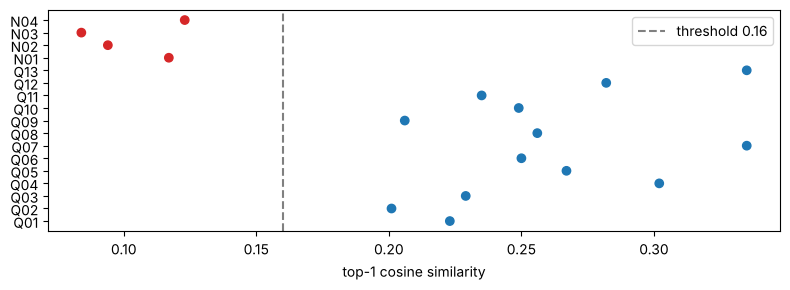

워크북 2에서 사용할 임계값: 0.16


In [11]:
# 점수 분포 그래프: 파란 점(문서에 있음)과 빨간 점(문서에 없음) 사이에
# 임계값 선이 오면 잘 구분된 것입니다. (그래프 글자는 영어로 표시)
import matplotlib.pyplot as plt

THRESHOLD = summary["threshold"]
colors = result["in_doc"].map({True: "tab:blue", False: "tab:red"})

plt.figure(figsize=(8, 3))
plt.scatter(result["score"], range(len(result)), c=colors)
plt.axvline(THRESHOLD, color="gray", linestyle="--",
            label=f"threshold {THRESHOLD}")
plt.yticks(range(len(result)), result["id"])
plt.xlabel("top-1 cosine similarity")
plt.legend()
plt.tight_layout()
plt.show()

print("워크북 2에서 사용할 임계값:", THRESHOLD)

> 🎓 **강의 포인트**
>
> - 파란 점(Q01~Q13)은 모두 0.2 이상, 빨간 점(N01~N04)은 모두 0.13 이하 → 점선 0.16이 두 그룹을 나눕니다.
> - 이 임계값은 **이 PDF와 이 CSV**에서 구한 값입니다. 문서가 바뀌면 다시 측정해야 합니다.

## 6. 직접 해 보기
아래 `my_question`을 바꿔 가며 실행하고 1순위 페이지와 점수를 기록하세요.

In [12]:
my_question = "겹침이 청크 크기보다 크면 어떻게 되나요?"

for rank, hit in enumerate(retrieve(index, my_question, top_k=3), 1):
    verdict = "근거 있음" if hit["score"] >= THRESHOLD else "임계값 미만"
    print(f"{rank}위 p.{hit['page']} 점수 {hit['score']:.3f} ({verdict})")
    print("   ", hit["text"][:80], "...")

1위 p.4 점수 0.286 (근거 있음)
    겹침( overlap) 은 이웃한 두 청크가 공유하는 단어 수입니다. 겹침을 두면 문장이 경계에서 잘리더라도 다음 청크에 그 내용이 다시 포함됩 ...
2위 p.4 점수 0.132 (임계값 미만)
    청킹 전략 청킹은 긴 문서를 검색하기 좋은 작은 구간으로 나누는 작업입니다. 문서 전체를 하나의 벡터로 만들면 여러 주제가 섞여서 질문과 정확히 ...
3위 p.9 점수 0.113 (임계값 미만)
    학습 과제와 제출 워크북 1에서는 CSV 평가 질문으로 검색 결과를 검증하고, 정답 페이지가 1순위에 나온 비율인 Top-1 정확도와 3순위 안 ...


> 🎓 **강의 포인트**
>
> - 1위 p.4 점수 0.286(근거 있음), 2·3위는 임계값 미만.
> - 학생에게 문서에 없는 질문(예: "도서관 운영 시간은?")도 넣어 보게 하고 점수를 비교합니다.

## 과제 (제출: 실행 화면 캡처 2장 + 아래 기록표)

| 항목 | size=60, char_wb | size=30, char_wb | size=60, word |
| --- | --- | --- | --- |
| 청크 수 | | | |
| Top-1 정확도 | | | |
| Top-3 정확도 | | | |
| 문서에 있는 질문 최저 점수 | | | |
| 문서에 없는 질문 최고 점수 | | | |

1. 정답 페이지를 놓친 질문(`top1 == False`)을 찾고, 왜 다른 페이지가 1위가 되었는지 설명하세요.
2. `word` 분석이 한국어에서 약한 이유를 `build_analyzer()` 결과를 근거로 설명하세요.
3. TF-IDF 검색이 6주차 의미 임베딩 검색과 다른 점을 두 가지 쓰세요.

## 과제 예시 답안 (강의자용)

| 항목 | size=60, char_wb | size=30, char_wb | size=60, word |
| --- | --- | --- | --- |
| 청크 수 | 22 | 39 | 22 |
| Top-1 정확도 | 0.923 | 0.923 | 0.538 |
| Top-3 정확도 | 1.0 | 1.0 | 0.846 |
| 문서에 있는 질문 최저 점수 | 0.201 | 0.216 | 0.0 |
| 문서에 없는 질문 최고 점수 | 0.123 | 0.148 | 0.0 |

1. Q03은 p.1(강의 운영 안내)에 "6주차 … 분류", "7주차 … 질의응답"이 함께 나와 1위가 p.1이 됨. 정답 p.2는 2위.
2. `word` 분석은 "청크를"과 "청크는"을 다른 단어로 봄 → 조사·어미가 붙는 한국어에서 일치 단어가 거의 없음. `build_analyzer()` 결과에서 `char_wb`는 `'청크'` 조각을 공유하는 것으로 확인.
3. ① TF-IDF는 글자 조각이 겹쳐야 점수가 생기고(표면 일치), 임베딩은 뜻이 비슷하면 다른 단어여도 가까움. ② TF-IDF는 문서 집합으로 사전을 새로 만드는 희소 벡터이고, 임베딩은 사전학습된 모델이 만드는 고정 길이 밀집 벡터.